In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

transactions = pd.read_csv("transactions.csv")
products = pd.read_csv("products.csv")
stores = pd.read_csv("stores.csv")
inventory = pd.read_csv("inventory.csv")
external = pd.read_csv("external_factors.csv")

print("Transactions:", transactions.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Inventory:", inventory.shape)
print("External factors:", external.shape)

print(transactions.head())


Transactions: (1801, 7)
Products: (12, 7)
Stores: (5, 5)
Inventory: (1800, 9)
External factors: (150, 7)
         date store product  quantity  selling_price  discount_percent  \
0  2026-09-01  S001    P001         5          320.0                 0   
1  2026-09-01  S001    P002         7           30.4                 5   
2  2026-09-01  S001    P003         9           36.0                10   
3  2026-09-01  S001    P004        11          145.0                 0   
4  2026-09-01  S001    P005         9          104.5                 5   

   promotion  
0          1  
1          0  
2          0  
3          0  
4          0  


In [4]:

# 1. Missing values
print("Missing values:")
print(transactions.isnull().sum())
print(external.isnull().sum())
print(products.isnull().sum())

# 2. Duplicate transactions
print("Duplicate transactions:",
      transactions.duplicated().sum())

# 3. Inconsistent category names
print("Categories before cleaning:")
print(products["category"].unique())

# 4. Invalid quantities and prices
print("Invalid quantities:",
      (transactions["quantity"] < 0).sum())

print("Invalid prices:",
      (transactions["selling_price"] <= 0).sum())

# 5. Inventory arithmetic mismatch
expected_closing = (
    inventory["opening"]
    + inventory["received"]
    - inventory["sold"]
)
print("Inventory mismatches:",
      (inventory["closing"] != expected_closing).sum())

Missing values:
date                0
store               0
product             1
quantity            0
selling_price       0
discount_percent    0
promotion           0
dtype: int64
date           0
store          0
weather        1
holiday        0
festival       0
weekend        0
local_event    0
dtype: int64
product            0
product_name       0
category           0
brand              0
price              0
shelf_life_days    0
supplier           0
dtype: int64
Duplicate transactions: 1
Categories before cleaning:
['Grocery' 'Dairy' 'Bakery' 'Personal care' 'Snacks' 'Home Care' 'produce'
 'Beverages']
Invalid quantities: 1
Invalid prices: 1
Inventory mismatches: 1


In [6]:
transactions = transactions.drop_duplicates().copy()

for data in [transactions, inventory, external]:
    data["date"] = pd.to_datetime(data["date"], errors="coerce")

transactions = transactions.dropna(
    subset=["date", "store", "product", "quantity", "selling_price"]
)

transactions = transactions[
    (transactions["quantity"] >= 0) &
    (transactions["selling_price"] > 0)
].copy()

products["category"] = (
    products["category"].astype("string").str.strip().str.title()
)

external["weather"] = external["weather"].fillna(
    external["weather"].mode()[0]
)

expected_closing = (
    inventory["opening"] +
    inventory["received"] -
    inventory["sold"]
)
inventory["closing"] = expected_closing
print("Transactions after cleaning:", transactions.shape)
print("Missing transaction values:")
print(transactions.isnull().sum())


Transactions after cleaning: (1797, 7)
Missing transaction values:
date                0
store               0
product             0
quantity            0
selling_price       0
discount_percent    0
promotion           0
dtype: int64


In [7]:
sales = transactions.merge(
    products, on="product", how="left"
)
sales = sales.merge(
    stores, on="store", how="left"
)
sales = sales.merge(
    external, on=["date", "store"], how="left"
)
sales = sales.merge(
    inventory,
    on=["date", "store", "product"],
    how="left",
    suffixes=("", "_inventory")
)
sales["revenue"] = (
    sales["quantity"] * sales["selling_price"]
)
print(sales.head())
print("Combined dataset shape:", sales.shape)


        date store product  quantity  selling_price  discount_percent  \
0 2026-09-01  S001    P001         5          320.0                 0   
1 2026-09-01  S001    P002         7           30.4                 5   
2 2026-09-01  S001    P003         9           36.0                10   
3 2026-09-01  S001    P004        11          145.0                 0   
4 2026-09-01  S001    P005         9          104.5                 5   

   promotion    product_name       category         brand  ...  festival  \
0          1        Rice 5kg        Grocery  DailyHarvest  ...         0   
1          0         Milk 1L          Dairy     FreshFarm  ...         0   
2          0           Bread         Bakery     BakeHouse  ...         0   
3          0  Cooking Oil 1L        Grocery    GoldenDrop  ...         0   
4          0   Shampoo 180ml  Personal Care      GlowCare  ...         0   

   weekend local_event opening received  sold closing reorder_level  \
0        0           1      35   

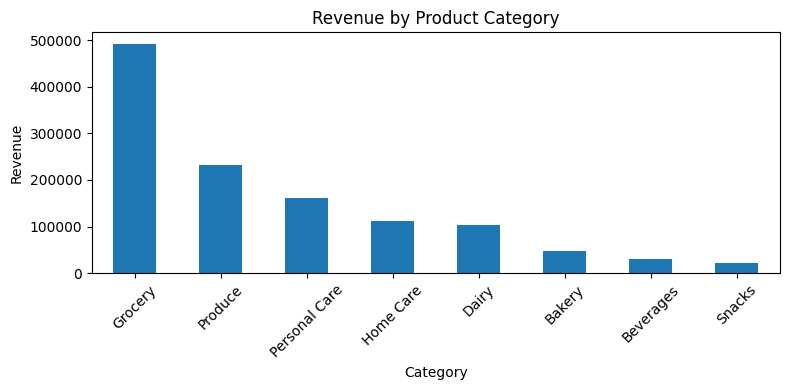

In [8]:

category_sales = (
    sales.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.plot(kind="bar", figsize=(8, 4))
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


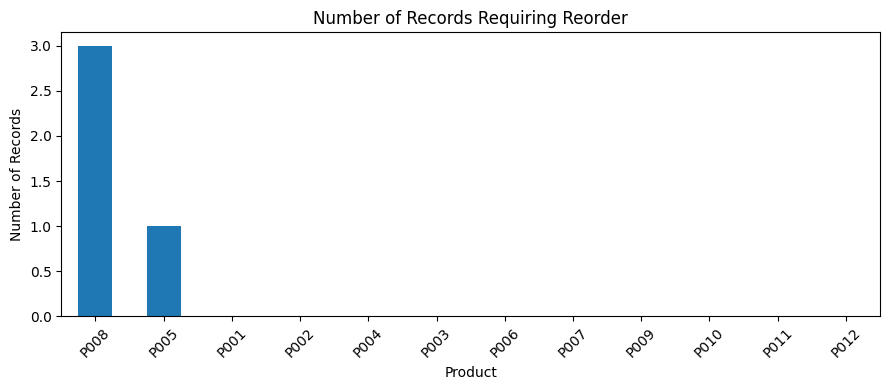

In [9]:

inventory["needs_reorder"] = (
    inventory["closing"] <= inventory["reorder_level"]
)
reorder_counts = (
    inventory.groupby("product")["needs_reorder"]
    .sum()
    .sort_values(ascending=False)
)
reorder_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Number of Records Requiring Reorder")
plt.xlabel("Product")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


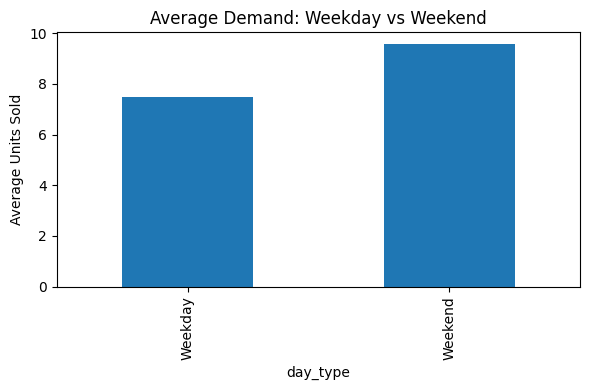

day_type
Weekday    7.466970
Weekend    9.554167
Name: quantity, dtype: float64


In [10]:

sales["day_type"] = np.where(
    sales["date"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

day_demand = sales.groupby("day_type")["quantity"].mean()
day_demand.plot(kind="bar", figsize=(6, 4))
plt.title("Average Demand: Weekday vs Weekend")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()
print(day_demand)

In [11]:

sales["month"] = sales["date"].dt.month
sales["day_of_week"] = sales["date"].dt.dayofweek
sales["is_weekend"] = (
    sales["day_of_week"] >= 5
).astype(int)
sales["discount_amount"] = (
    sales["selling_price"] *
    sales["discount_percent"] / 100
)
sales["stock_coverage_days"] = (
    sales["closing"] /
    sales["sold"].replace(0, np.nan)
)
print(sales[[
    "date", "product", "quantity",
    "revenue", "month", "is_weekend",
    "stock_coverage_days"
]].head())

        date product  quantity  revenue  month  is_weekend  \
0 2026-09-01    P001         5   1600.0      9           0   
1 2026-09-01    P002         7    212.8      9           0   
2 2026-09-01    P003         9    324.0      9           0   
3 2026-09-01    P004        11   1595.0      9           0   
4 2026-09-01    P005         9    940.5      9           0   

   stock_coverage_days  
0             8.000000  
1             5.000000  
2             4.444444  
3             4.090909  
4             7.111111  
